# 03 · ¿Dónde le gana tiempo un piloto a otro?

Este notebook compara la **vuelta de la pole** de Bahréin 2024: la de Max Verstappen (VER) contra la de Charles Leclerc (LEC), las mejores de cada uno en la Q3. Muestra, metro a metro, dónde uno saca tiempo al otro.

Los datos vienen de [OpenF1](https://openf1.org). El análisis vive en `f1analytics.analisis.telemetria` y los gráficos en `f1analytics.graficos.telemetria`; aquí solo se usan y se dibujan.

> **Cómo se lee.** El piloto **A** (VER) es la referencia y el **B** (LEC) el que se compara. El *delta* es el tiempo que B lleva de más sobre A en cada punto de la pista: **positivo** si B va por detrás, negativo si va por delante. Su valor al final de la vuelta es la diferencia oficial de tiempo.

> **Qué tan exacto es.** La telemetría pública de OpenF1 tiene unas 3,7 muestras por segundo (una cada ~20 m a 250 km/h). El delta final se ajusta a los tiempos oficiales, pero a mitad de vuelta es una estimación: en la sección 4 se mide cuánto se equivoca.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from f1analytics.analisis.circuito import orientar_circuito, posicion_curvas
from f1analytics.analisis.telemetria import (
    alinear_vueltas,
    delta_tiempo,
    ganador_por_minisector,
    resumen_telemetria,
)
from f1analytics.datos.cargador import Cargador
from f1analytics.datos.circuitos import circuito
from f1analytics.datos.cliente import ClienteOpenF1
from f1analytics.datos.telemetria_vuelta import telemetria_de_vuelta, vuelta_rapida
from f1analytics.graficos.estilo import aplicar_estilo
from f1analytics.graficos.telemetria import mapa_minisectores, trazas

aplicar_estilo()
pd.options.display.float_format = "{:,.3f}".format
CARPETA_FIGURAS = Path("../../docs/figuras")  # las figuras del README

cargador = Cargador(ClienteOpenF1())

## 1. Las dos vueltas

Se busca la clasificación del Gran Premio de Bahréin de 2024 y, de cada piloto, su vuelta más rápida **dentro de la Q3**. Esto importa: la mejor vuelta de la sesión no siempre es de la Q3 (en Monza, la de Verstappen fue en la Q2).

Cada vuelta se baja con su telemetría: velocidad, acelerador, freno y posición, con la distancia recorrida desde la meta.

In [2]:
ANIO = 2024
calendario = cargador.calendario(ANIO)
evento = int(calendario.loc[calendario["nombre"] == "Bahrain Grand Prix", "evento"].iloc[0])
sesion = cargador.buscar_sesion(ANIO, evento, "Qualifying")
pilotos = cargador.pilotos(sesion).set_index("numero")["codigo"]

PILOTO_A, PILOTO_B = 1, 16  # VER (referencia) y LEC
nombre_a, nombre_b = pilotos[PILOTO_A], pilotos[PILOTO_B]

vueltas, tels, filas = {}, {}, {}
for piloto in (PILOTO_A, PILOTO_B):
    vueltas[piloto] = vuelta_rapida(cargador, sesion, piloto, "Q3")
    filas[piloto] = cargador.vueltas(sesion, piloto).set_index("vuelta").loc[vueltas[piloto]]
    tels[piloto] = telemetria_de_vuelta(cargador, sesion, piloto, vueltas[piloto])

resumen_vueltas = pd.DataFrame(
    {
        "piloto": [nombre_a, nombre_b],
        "vuelta": [vueltas[PILOTO_A], vueltas[PILOTO_B]],
        "tiempo_s": [filas[PILOTO_A]["tiempo_vuelta_s"], filas[PILOTO_B]["tiempo_vuelta_s"]],
        "muestras": [len(tels[PILOTO_A]), len(tels[PILOTO_B])],
        "distancia_integrada_m": [t["distancia_m"].iloc[-1] for t in tels.values()],
    }
)
print(f"Sesión {sesion}: clasificación de Bahréin {ANIO}")
resumen_vueltas

Sesión 9468: clasificación de Bahréin 2024


,piloto,vuelta,tiempo_s,muestras,distancia_integrada_m
0,VER,16,89.179,344,"5,328.904"
1,LEC,18,89.407,345,"5,360.647"


## 2. Las dos vueltas sobre la misma distancia

Las muestras de los dos pilotos no caen en los mismos metros, así que no se pueden restar tal cual. `alinear_vueltas` lleva cada vuelta a una rejilla de **un punto cada 5 metros** y junta las dos tablas (`velocidad_a`, `velocidad_b`…).

Antes de eso hay un detalle: la distancia sale de integrar la velocidad y se equivoca un poco (~1 %) y distinto en cada vuelta. Como las dos recorren la misma pista, `alinear_vueltas` las estira para que midan lo mismo (el promedio de las dos). Se gira el mapa antes de alinear, como en el notebook 01, para dibujarlo después con la orientación de la transmisión.

In [3]:
trazado = circuito(63, ANIO)  # Sakhir
orientadas = {p: orientar_circuito(tel, trazado.rotacion) for p, tel in tels.items()}
alineadas = alinear_vueltas(orientadas[PILOTO_A], orientadas[PILOTO_B])
curvas = posicion_curvas(trazado.curvas, trazado.rotacion)

largo = alineadas["distancia_m"].iloc[-1]
estirada = [abs(1 - largo / t["distancia_m"].iloc[-1]) for t in tels.values()]
print(f"{len(alineadas)} puntos, uno cada 5 m; largo común: {largo:,.0f} m")
print(f"Se estiró cada vuelta {estirada[0]:.2%} y {estirada[1]:.2%}")
columnas = ["distancia_m", "velocidad_a", "velocidad_b", "acelerador_a", "acelerador_b"]
alineadas[[*columnas, "freno_a", "freno_b"]].iloc[::200]

1070 puntos, uno cada 5 m; largo común: 5,345 m
Se estiró cada vuelta 0.30% y 0.30%


,distancia_m,velocidad_a,velocidad_b,acelerador_a,acelerador_b,freno_a,freno_b
0,0.000,301.000,294.000,100.000,99.000,0,0
200,"1,000.000",253.793,255.743,100.000,99.000,0,0
400,"2,000.000",246.042,247.956,100.000,99.000,0,0
600,"3,000.000",275.053,275.550,100.000,99.000,0,0
800,"4,000.000",197.173,182.069,0.000,8.991,100,100
1000,"5,000.000",212.108,221.260,100.000,99.000,0,0


## 3. El delta, y por qué se ajusta

`delta_tiempo` calcula cuánto tarda cada piloto en llegar a cada metro (integrando `distancia / velocidad`) y resta los dos tiempos. Pero con ~3,7 muestras por segundo, esa integración acumula error y el total no coincide con el cronometrado.

La solución es escalar el tiempo de cada vuelta para que termine justo en su duración oficial (`lap_duration`). Así el delta final es **exactamente** la diferencia oficial. Se muestra la diferencia entre el delta sin ajustar y el ajustado.

In [4]:
oficial = filas[PILOTO_B]["tiempo_vuelta_s"] - filas[PILOTO_A]["tiempo_vuelta_s"]
crudo = delta_tiempo(alineadas)
tiempo_a, tiempo_b = filas[PILOTO_A]["tiempo_vuelta_s"], filas[PILOTO_B]["tiempo_vuelta_s"]
delta = delta_tiempo(alineadas, tiempo_a, tiempo_b)

pd.Series(
    {
        "Diferencia oficial de tiempo de vuelta": oficial,
        "Delta final sin ajustar": crudo.iloc[-1],
        "Delta final ajustado": delta.iloc[-1],
        "Mayor cambio que hace el ajuste": (delta - crudo).abs().max(),
    },
    name="segundos",
).to_frame()

,segundos
Diferencia oficial de tiempo de vuelta,0.228
Delta final sin ajustar,-0.119
Delta final ajustado,0.228
Mayor cambio que hace el ajuste,0.347


## 4. ¿Qué tan bien está el delta a mitad de vuelta?

Al final de la vuelta el delta es exacto porque se ajusta a ese dato. Pero a mitad de vuelta no hay nada que lo ajuste, así que hay que medirlo con una verdad independiente: **los tiempos oficiales de sector**. OpenF1 dice cuánto llevaba cada piloto al terminar el sector 1 y el 2. Se busca el punto de la pista donde cada coche los cruzó (según su reloj) y se compara el delta ahí con la diferencia oficial.

In [5]:
largo = alineadas["distancia_m"].iloc[-1]
estiramiento = {p: largo / tels[p]["distancia_m"].iloc[-1] for p in tels}

validacion = []
for corte in (1, 2):
    columnas = [f"sector_{i}_s" for i in range(1, corte + 1)]
    oficial_a = filas[PILOTO_A][columnas].sum()
    oficial_b = filas[PILOTO_B][columnas].sum()
    cruces = []
    for piloto, oficial_piloto in ((PILOTO_A, oficial_a), (PILOTO_B, oficial_b)):
        tel = tels[piloto]
        cruces.append(
            np.interp(oficial_piloto, tel["tiempo_s"], tel["distancia_m"]) * estiramiento[piloto]
        )
    punto = sum(cruces) / 2
    estimado = float(np.interp(punto, alineadas["distancia_m"], delta))
    validacion.append(
        {
            "final del sector": corte,
            "distancia_m": punto,
            "delta oficial_s": oficial_b - oficial_a,
            "delta estimado_s": estimado,
            "error_s": estimado - (oficial_b - oficial_a),
        }
    )
pd.DataFrame(validacion)

,final del sector,distancia_m,delta oficial_s,delta estimado_s,error_s
0,1,"1,761.139",0.227,0.243,0.016
1,2,"3,953.489",0.234,0.230,-0.004


El error es de unas centésimas. Se probó lo mismo en 6 comparaciones de la Q3 de 5 carreras de 2024 (Bahréin, Italia, Mónaco, España y Gran Bretaña), 12 cruces de sector en total: el error medio fue de **0,03 s** y el máximo de **0,11 s**. Es lo bastante bueno para decir quién fue más rápido en un tramo largo, no para discutir una diferencia de una milésima.

## 5. Trazas: velocidad, acelerador, freno y delta

Los cuatro paneles comparten la distancia. Cuando el delta sube, A le está sacando tiempo a B; cuando baja, B lo recupera.

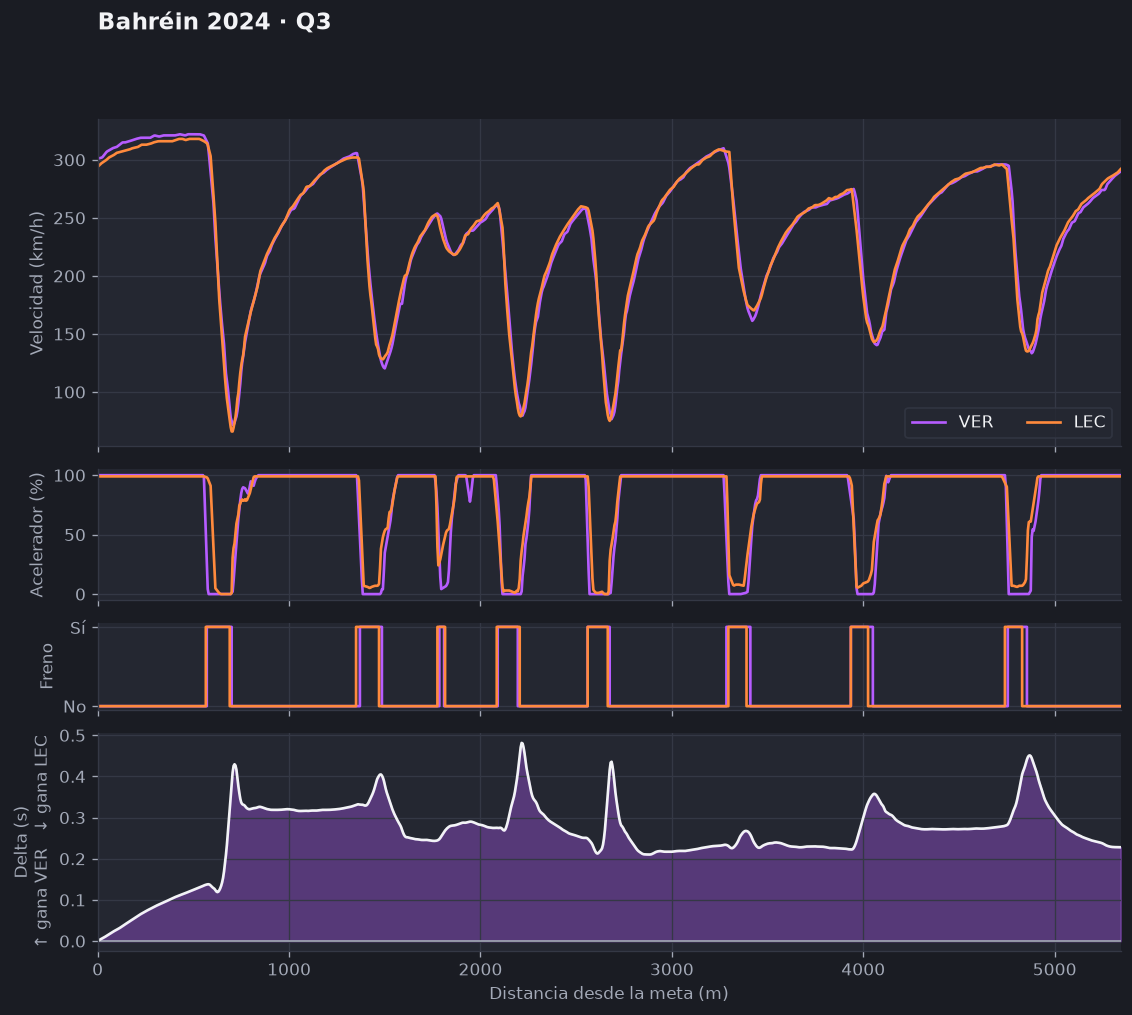

In [6]:
fig = trazas(alineadas, delta, nombre_a=nombre_a, nombre_b=nombre_b, titulo="Bahréin 2024 · Q3")
fig.savefig(CARPETA_FIGURAS / "telemetria-trazas.png", bbox_inches="tight")
plt.show()

## 6. Los 25 minisectores

Los minisectores oficiales (los de la transmisión) varían entre 21 y 28 según el circuito y casi la mitad de los circuitos no tiene ninguno, así que aquí se parte la vuelta en **25 tramos de igual longitud**. En cada tramo gana quien lo recorre en menos tiempo, es decir, quien hace que el delta suba o baje. Una diferencia menor de 0,01 s se cuenta como empate: está por debajo del error medido arriba.

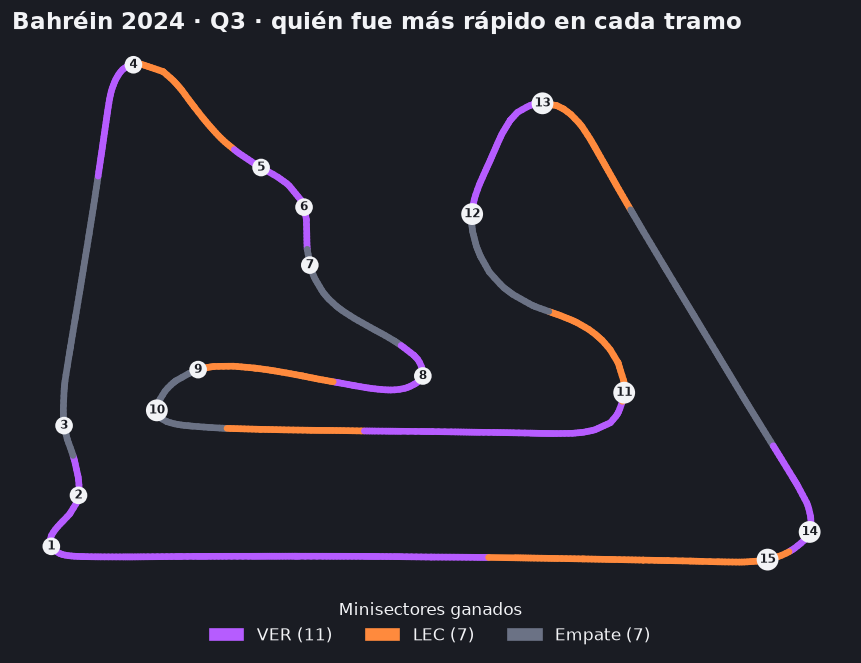

,sector,inicio_m,fin_m,diferencia_s,ganador
0,0,0.000,213.791,0.062,VER
1,1,213.791,427.582,0.049,VER
2,2,427.582,641.373,0.019,VER
3,3,641.373,855.164,0.196,VER
4,4,855.164,"1,068.955",-0.009,empate
5,5,"1,068.955","1,282.746",0.006,empate
6,6,"1,282.746","1,496.537",0.064,VER
7,7,"1,496.537","1,710.328",-0.141,LEC
8,8,"1,710.328","1,924.119",0.042,VER
9,9,"1,924.119","2,137.910",-0.006,empate


In [7]:
ganadores = ganador_por_minisector(alineadas, delta)
fig = mapa_minisectores(
    alineadas,
    ganadores,
    nombre_a=nombre_a,
    nombre_b=nombre_b,
    curvas=curvas,
    titulo="Bahréin 2024 · Q3 · quién fue más rápido en cada tramo",
)
fig.savefig(CARPETA_FIGURAS / "telemetria-minisectores.png", bbox_inches="tight")
plt.show()
quien = {"a": nombre_a, "b": nombre_b, "empate": "empate"}
ganadores.assign(ganador=ganadores["ganador"].map(quien))

## 7. Conclusión

`resumen_telemetria` devuelve solo datos; la web los convierte en una frase en español o en inglés. Aquí se arma una a mano, con sus límites.

In [8]:
resumen = resumen_telemetria(alineadas, delta, ganadores)
nombres = {"a": nombre_a, "b": nombre_b}
ganador = resumen["ganador"]
perdedor = "b" if ganador == "a" else "a"
diferencia = abs(resumen["delta_final_s"])
print(f"{nombres[ganador]} fue {diferencia:.3f} s más rápido que {nombres[perdedor]} en la vuelta.")
ganados = resumen["sectores_ganados"]
print(
    f"{nombres[ganador]} ganó {ganados[ganador]} de los 25 minisectores; "
    f"{nombres[perdedor]} ganó {ganados[perdedor]} y empataron {ganados['empate']}."
)
for letra in ("a", "b"):
    ventaja = resumen["mayor_ventaja"][letra]
    if ventaja:
        tramo = f"{ventaja['inicio_m']:,.0f} y los {ventaja['fin_m']:,.0f} m"
        print(f"{nombres[letra]} sacó más tiempo entre los {tramo}: {ventaja['ventaja_s']:.3f} s.")
for letra in ("a", "b"):
    print(
        f"{nombres[letra]}: {resumen['pct_a_fondo'][letra]:.0f} % de la vuelta a fondo, "
        f"máxima {resumen['vel_maxima'][letra]['kmh']:.0f} km/h, "
        f"mínima {resumen['vel_minima'][letra]['kmh']:.0f} km/h."
    )
resumen

VER fue 0.228 s más rápido que LEC en la vuelta.
VER ganó 11 de los 25 minisectores; LEC ganó 7 y empataron 7.
VER sacó más tiempo entre los 641 y los 855 m: 0.196 s.
LEC sacó más tiempo entre los 1,497 y los 1,710 m: 0.141 s.
VER: 70 % de la vuelta a fondo, máxima 322 km/h, mínima 72 km/h.
LEC: 73 % de la vuelta a fondo, máxima 318 km/h, mínima 66 km/h.


{'delta_final_s': 0.22799999999998022,
 'ganador': 'a',
 'sectores_ganados': {'a': 11, 'b': 7, 'empate': 7},
 'mayor_ventaja': {'a': {'sector': 3,
   'inicio_m': 641.3730833333336,
   'fin_m': 855.1641111111114,
   'ventaja_s': 0.19577838956585641},
  'b': {'sector': 7,
   'inicio_m': 1496.537194444445,
   'fin_m': 1710.3282222222228,
   'ventaja_s': 0.1410307089933136}},
 'pct_a_fondo': {'a': 70.2513240798355, 'b': 72.59005646349623},
 'vel_maxima': {'a': {'kmh': 322.0, 'distancia_m': 475.0},
  'b': {'kmh': 318.0, 'distancia_m': 430.0}},
 'vel_minima': {'a': {'kmh': 71.56367951812696, 'distancia_m': 710.0},
  'b': {'kmh': 66.0, 'distancia_m': 705.0}}}

### Lo que este análisis no puede decir

- **Cuánto tardó cada piloto en cada tramo.** El delta dice quién fue más rápido, no por qué: una diferencia puede ser una mejor frenada, una mejor trazada o que el otro levantó el pie.
- **Diferencias muy pequeñas.** Con ~3,7 muestras por segundo el delta tiene un error medio de 0,03 s a mitad de vuelta; los minisectores con menos de 0,01 s se declaran empate.
- **Los picos del delta en las frenadas fuertes.** En las trazas, el delta sube de golpe en cada frenada y baja justo después. Es en parte ruido: con una muestra cada ~20 m, el punto más lento de la curva se pierde o se exagera en una de las dos vueltas. Lo que cuenta es el nivel al que se estabiliza el delta *después* de la curva, no el pico.
- **Dos vueltas con condiciones distintas.** La Q3 tiene pista, temperatura y gomas casi iguales para todos, pero una vuelta con tráfico o con una goma distinta no se puede corregir.
- **La velocidad máxima y mínima.** Salen de muestras separadas ~20 m, así que pueden quedar por debajo del punto real.